Synthetic stock-like data created successfully.

Analyzing: tanh | Sequence Length: 10
Loss: 0.0504
Gradient Norms: [0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.55016136]

Analyzing: tanh | Sequence Length: 50
Loss: 2.0718
Gradient Norms: [0.        0.        0.        0.        0.        0.        0.
 0.        0.        0.        0.        0.        0.        0.
 0.        0.        0.        0.        0.        0.        0.
 0.        0.        0.        0.        0.        0.        0.
 0.        0.        0.        0.        0.        0.        0.
 0.        0.        0.        0.        0.        0.        0.
 0.        0.        0.        0.        0.        0.        0.
 3.7569246]

Analyzing: tanh | Sequence Length: 100
Loss: 0.0009
Gradient Norms: [0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.  

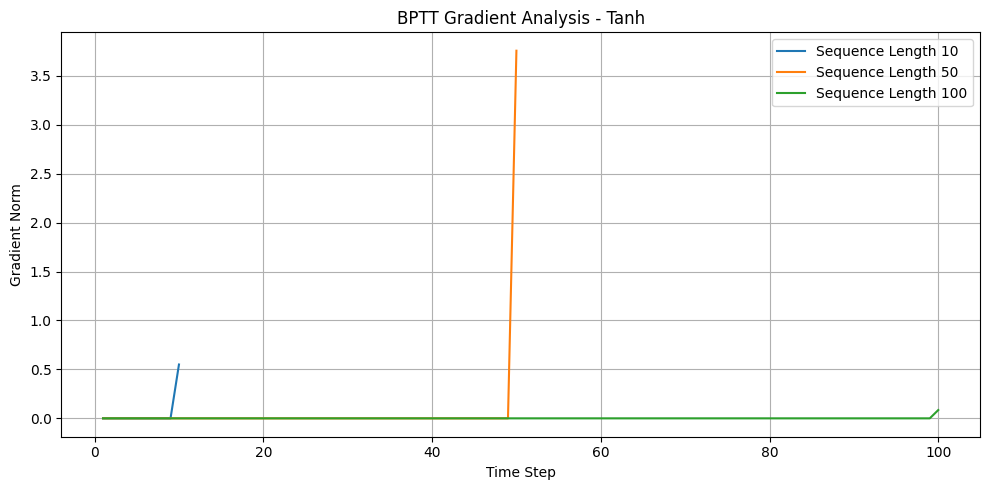

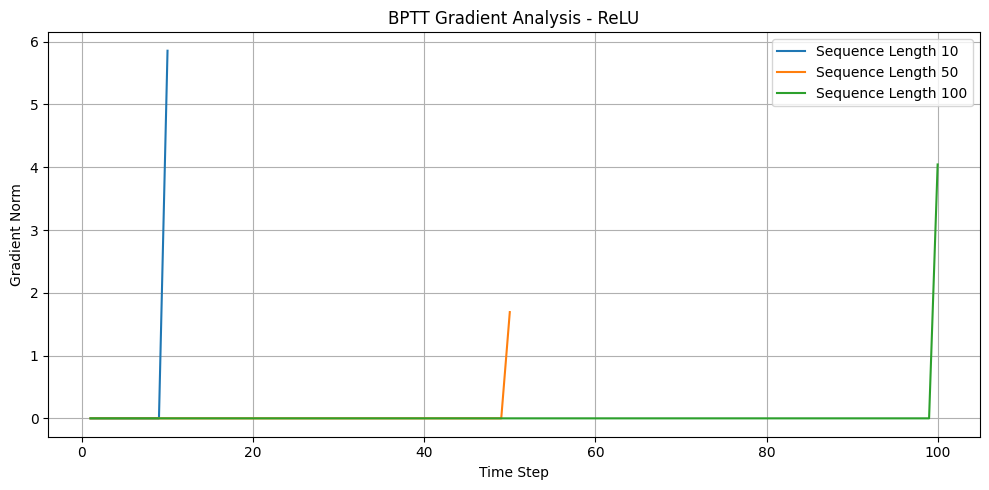

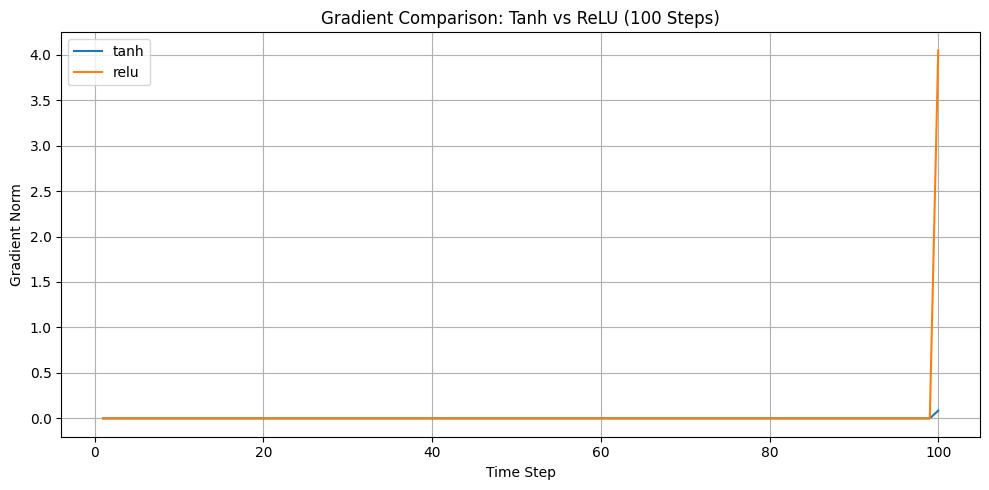


GRADIENT ANALYSIS SUMMARY
tanh | Length: 10 | Maximum: 0.550161 | Minimum: 0.0
tanh | Length: 50 | Maximum: 3.756925 | Minimum: 0.0
tanh | Length: 100 | Maximum: 0.084726 | Minimum: 0.0
relu | Length: 10 | Maximum: 5.856224 | Minimum: 0.0
relu | Length: 50 | Maximum: 1.692574 | Minimum: 0.0
relu | Length: 100 | Maximum: 4.044336 | Minimum: 0.0

Experiment 15 completed successfully!


In [19]:
# EXPERIMENT 15: BPTT FLOW AND GRADIENT ANALYSIS

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models

# ----------------------------------------
# 1. CREATE SYNTHETIC SEQUENCE DATA
# ----------------------------------------

tf.keras.utils.set_random_seed(42)
np.random.seed(42)

data = np.cumsum(np.random.randn(500)).astype("float32")

# Normalize data
data = (data - data.mean()) / data.std()

print("Synthetic stock-like data created successfully.")

# ----------------------------------------
# 2. FUNCTION TO CREATE RNN MODEL
# ----------------------------------------

def build_rnn(sequence_length, activation):

    model = models.Sequential([
        layers.Input(shape=(sequence_length, 1)),
        layers.SimpleRNN(
            16,
            activation=activation,
            return_sequences=True
        ),
        layers.Dense(1)
    ])

    return model

# ----------------------------------------
# 3. GRADIENT ANALYSIS
# ----------------------------------------

sequence_lengths = [10, 50, 100]
activations = ["tanh", "relu"]

gradient_results = {}

for activation in activations:

    for seq_len in sequence_lengths:

        print("\nAnalyzing:", activation,
              "| Sequence Length:", seq_len)

        # Prepare one sequence
        x = data[:seq_len].reshape(1, seq_len, 1)
        x = tf.constant(x)

        target = tf.constant([[data[seq_len]]])

        model = build_rnn(seq_len, activation)

        with tf.GradientTape() as tape:

            # Get hidden states for all time steps
            hidden_sequence = model.layers[0](x)

            # Final hidden state
            final_hidden = hidden_sequence[:, -1, :]

            # Prediction from final hidden state
            prediction = model.layers[1](final_hidden)

            # Loss
            loss = tf.reduce_mean(
                tf.square(prediction - target)
            )

        # Gradient of loss with respect to hidden states
        gradients = tape.gradient(loss, hidden_sequence)

        # Calculate gradient norm at each time step
        gradient_norms = tf.norm(
            gradients, axis=2
        ).numpy().flatten()

        gradient_results[(activation, seq_len)] = gradient_norms

        print("Loss:", round(float(loss.numpy()), 4))
        print("Gradient Norms:", gradient_norms)

# ----------------------------------------
# 4. PLOT GRADIENT NORMS FOR TANH
# ----------------------------------------

plt.figure(figsize=(10, 5))

for seq_len in sequence_lengths:

    values = gradient_results[("tanh", seq_len)]

    plt.plot(
        range(1, seq_len + 1),
        values,
        label=f"Sequence Length {seq_len}"
    )

plt.title("BPTT Gradient Analysis - Tanh")
plt.xlabel("Time Step")
plt.ylabel("Gradient Norm")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ----------------------------------------
# 5. PLOT GRADIENT NORMS FOR RELU
# ----------------------------------------

plt.figure(figsize=(10, 5))

for seq_len in sequence_lengths:

    values = gradient_results[("relu", seq_len)]

    plt.plot(
        range(1, seq_len + 1),
        values,
        label=f"Sequence Length {seq_len}"
    )

plt.title("BPTT Gradient Analysis - ReLU")
plt.xlabel("Time Step")
plt.ylabel("Gradient Norm")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ----------------------------------------
# 6. COMPARE TANH AND RELU
# ----------------------------------------

plt.figure(figsize=(10, 5))

for activation in activations:

    values = gradient_results[(activation, 100)]

    plt.plot(
        range(1, 101),
        values,
        label=activation
    )

plt.title("Gradient Comparison: Tanh vs ReLU (100 Steps)")
plt.xlabel("Time Step")
plt.ylabel("Gradient Norm")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ----------------------------------------
# 7. DISPLAY SUMMARY
# ----------------------------------------

print("\nGRADIENT ANALYSIS SUMMARY")

for activation in activations:

    for seq_len in sequence_lengths:

        values = gradient_results[(activation, seq_len)]

        print(
            activation,
            "| Length:", seq_len,
            "| Maximum:", round(float(np.max(values)), 6),
            "| Minimum:", round(float(np.min(values)), 6)
        )

print("\nExperiment 15 completed successfully!")